# Fresnel coefficients

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-06.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Reflection and Transmission Fresnel coefficients


In [15]:
### Define parameters
ni = 1.0  # Refractive index of incident medium (air)
nt = 1.33  # Refractive index of transmitted medium (water)
numangles2 = 256

theta_i_deg2 = np.linspace(0,90,numangles2) # Incident angles in degrees
theta_i2 = np.radians(theta_i_deg2) # Incident angle in radians
theta_t2 = np.arcsin(ni / nt * np.sin(theta_i2)) # Law of Refraction to solve for transmitted angle

# test for angles above critical angle (leading to NaN values)
critical_angle2 = np.arcsin(nt/ni) if ni > nt else np.pi/2
test_critical2 = theta_i2 > critical_angle2
theta_t2[test_critical2] = np.pi/2  # set transmitted angle to NaN for angles above critical angle

# Fresnel coefficients
tperp2 = 2 * ni * np.cos(theta_i2) / (ni * np.cos(theta_i2) + nt * np.cos(theta_t2))
rperp2 = (ni * np.cos(theta_i2) - nt * np.cos(theta_t2)) / (ni * np.cos(theta_i2) + nt * np.cos(theta_t2))

tpar2 = 2 * ni * np.cos(theta_i2) / (ni * np.cos(theta_t2) + nt * np.cos(theta_i2))
rpar2 = (nt * np.cos(theta_i2) - ni * np.cos(theta_t2)) / (ni * np.cos(theta_t2) + nt * np.cos(theta_i2))

# Set coefficients to zero during TIR to handle the case correctly
tperp2[test_critical2] = 0
rperp2[test_critical2] = 1 
tpar2[test_critical2] = 0
rpar2[test_critical2] = 1

# Reflectivity and Transmissivity formulas
Rperp2 = rperp2**2
Rpar2 = rpar2**2
Tperp2 = tperp2**2 * nt * np.cos(theta_t2) / (ni * np.cos(theta_i2))
Tpar2 = tpar2**2 * nt * np.cos(theta_t2) / (ni * np.cos(theta_i2))


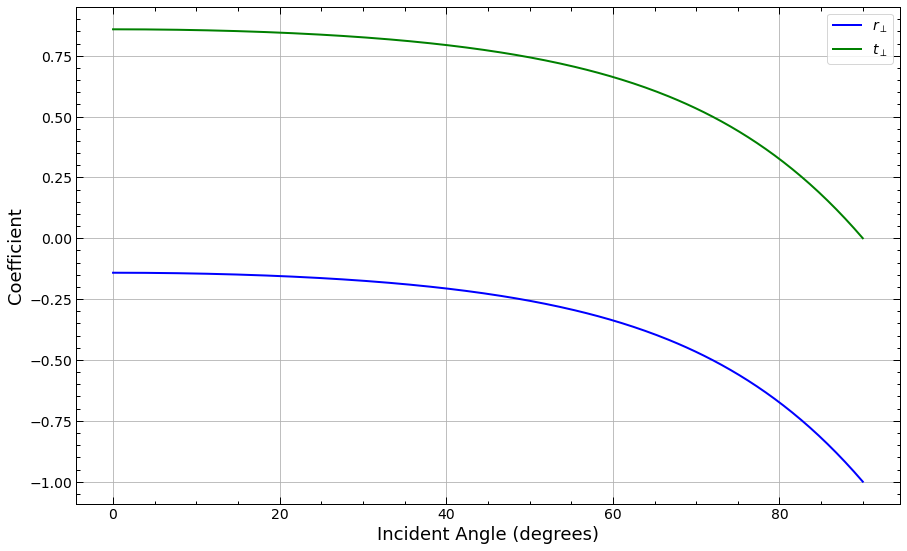

In [16]:
### Plot: Perpendicular Polarization

fig1, ax1 = plt.subplots(figsize=(8*1.618,8))

ax1.plot(theta_i_deg2, rperp2, label=r'$r_{\perp}$', color='blue', linewidth=2)
ax1.plot(theta_i_deg2, tperp2, label=r'$t_{\perp}$', color='green', linewidth=2)

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1, labelsize=14)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# Frame and labels
ax1.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax1.set_ylabel('Coefficient', fontsize=18)
# ax1.set_title('Perpendicular Polarization')

ax1.legend(fontsize=14)
ax1.grid(True)

fig1.tight_layout()
fig1.show()


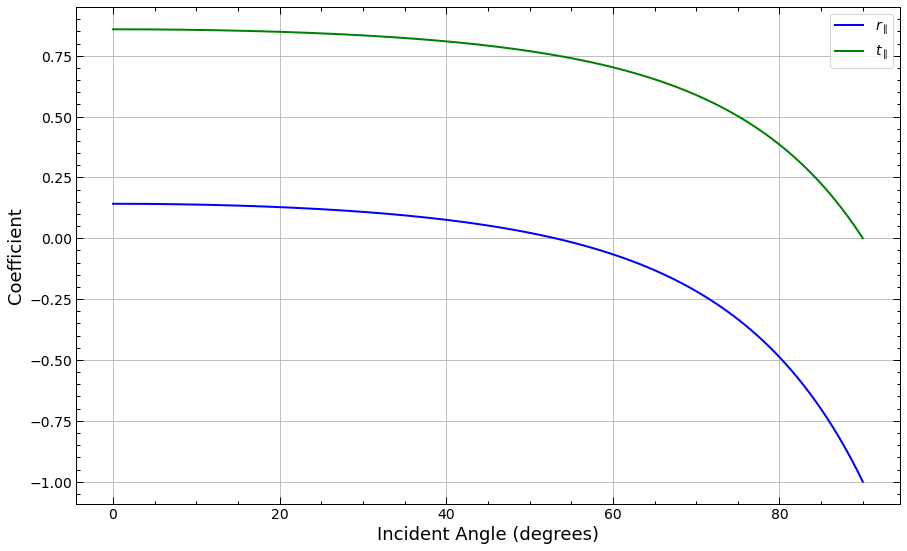

In [17]:
### Plot: Parallel Polarization

fig2, ax2 = plt.subplots(figsize=(8*1.618,8))

ax2.plot(theta_i_deg2, rpar2, label=r'$r_{\parallel}$', color='blue', linewidth=2)
ax2.plot(theta_i_deg2, tpar2, label=r'$t_{\parallel}$', color='green', linewidth=2)

# set the tick mark parameters
ax2.minorticks_on()
ax2.tick_params(which='both',direction="in",width=1, labelsize=14)
ax2.tick_params(which='major',length=7)
ax2.tick_params(which='minor',length=3.5)
ax2.xaxis.set_ticks_position('both')
ax2.yaxis.set_ticks_position('both')

# Frame and labels
ax2.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax2.set_ylabel('Coefficient', fontsize=18)
# ax2.set_title('Perpendicular Polarization')

ax2.legend(fontsize=14)
ax2.grid(True)

fig2.tight_layout()
fig2.show()


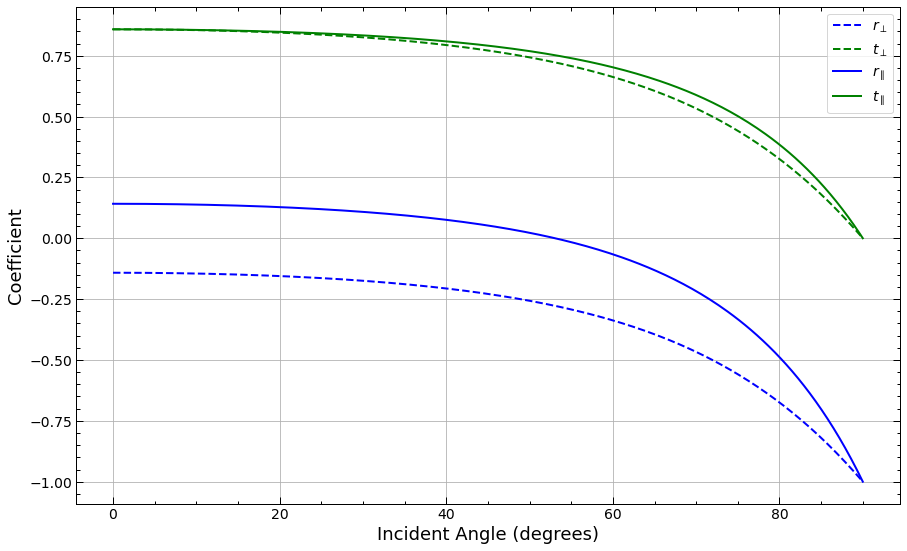

In [18]:
### Plot: Both Polarizations

fig3, ax3 = plt.subplots(figsize=(8*1.618,8))

ax3.plot(theta_i_deg2, rperp2, label=r'$r_{\perp}$', color='blue', linewidth=2, linestyle='--')
ax3.plot(theta_i_deg2, tperp2, label=r'$t_{\perp}$', color='green', linewidth=2, linestyle='--')
ax3.plot(theta_i_deg2, rpar2, label=r'$r_{\parallel}$', color='blue', linewidth=2)
ax3.plot(theta_i_deg2, tpar2, label=r'$t_{\parallel}$', color='green', linewidth=2)

# set the tick mark parameters
ax3.minorticks_on()
ax3.tick_params(which='both',direction="in",width=1, labelsize=14)
ax3.tick_params(which='major',length=7)
ax3.tick_params(which='minor',length=3.5)
ax3.xaxis.set_ticks_position('both')
ax3.yaxis.set_ticks_position('both')

# Frame and labels
ax3.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax3.set_ylabel('Coefficient', fontsize=18)
# ax3.set_title('Both Polarizations')

ax3.legend(fontsize=14)
ax3.grid(True)

fig3.tight_layout()
fig3.show()


### Interactive plot with `matplotlib`

In [19]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_fresnel(ni, nt):
    plt.close('all') # Clear memory to prevent lag
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # --- MATH LOGIC ---
    numangles = 256
    theta_i_deg = np.linspace(0, 90, numangles)
    theta_i = np.radians(theta_i_deg)
    
    sin_t = ni / nt * np.sin(theta_i)
    critical_angle_rad = np.arcsin(nt/ni) if ni > nt else np.pi/2
    test_tir = theta_i > critical_angle_rad
    
    theta_t = np.arcsin(np.clip(sin_t, -1, 1))
    theta_t[test_tir] = np.pi/2 

    cos_i = np.cos(theta_i)
    cos_t = np.cos(theta_t)
    
    # Fresnel coefficients (using LaTeX for perfect subscripts/symbols)
    # Perpendicular (s-pol)
    r_perp = (ni * cos_i - nt * cos_t) / (ni * cos_i + nt * cos_t)
    t_perp = (2 * ni * cos_i) / (ni * cos_i + nt * cos_t)
    
    # Parallel (p-pol)
    r_par = (nt * cos_i - ni * cos_t) / (nt * cos_i + ni * cos_t)
    t_par = (2 * ni * cos_i) / (nt * cos_i + ni * cos_t)

    # TIR conditions
    r_perp[test_tir], t_perp[test_tir] = 1.0, 0.0
    r_par[test_tir], t_par[test_tir] = 1.0, 0.0

    # --- PLOTTING WITH LATEX LABELS ---
    # r_$\perp$ creates the perpendicular symbol in a subscript
    ax.plot(theta_i_deg, r_perp, label=r'$r_{\perp}$ (s-pol)', color='blue', linewidth=2, linestyle='--')
    ax.plot(theta_i_deg, t_perp, label=r'$t_{\perp}$ (s-pol)', color='green', linewidth=2, linestyle='--')
    ax.plot(theta_i_deg, r_par, label=r'$r_{\parallel}$ (p-pol)', color='blue', linewidth=2)
    ax.plot(theta_i_deg, t_par, label=r'$t_{\parallel}$ (p-pol)', color='green', linewidth=2)

    if ni > nt:
        # \theta_c creates the theta symbol with a 'c' subscript
        crit_deg = np.degrees(critical_angle_rad)
        ax.axvline(crit_deg, color='red', linestyle=':', alpha=0.5, label=fr'$\theta_c = {crit_deg:.1f}^\circ$')

    # Styling
    ax.set_xlabel('Incident Angle (degrees)', fontsize=18)
    ax.set_ylabel('Coefficient', fontsize=18)
    ax.set_ylim(-1.1, 2.1)
    ax.set_xlim(0, 90)
    ax.grid(True, linestyle=':', alpha=0.6)
    
    ax.tick_params(which='both', direction="in", width=1, labelsize=14)
    ax.minorticks_on()
    
    # Putting the legend outside or in a corner to avoid overlapping lines
    ax.legend(fontsize=12, loc='upper left', frameon=True)
    
    plt.show()

# Set continuous_update=False to ensure the figure only generates when you STOP sliding
interact(
    plot_fresnel, 
    ni=FloatSlider(min=1.0, max=2.5, step=0.05, value=1.5, description='n₁ (incident)', continuous_update=False),
    nt=FloatSlider(min=1.0, max=2.5, step=0.05, value=1.0, description='n₂ (transmitted)', continuous_update=False)
);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-06-coefficients_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-06.html) (direct link: [ch02-06-coefficients_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-06-coefficients_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.

## Reflectivity and Transmissivity

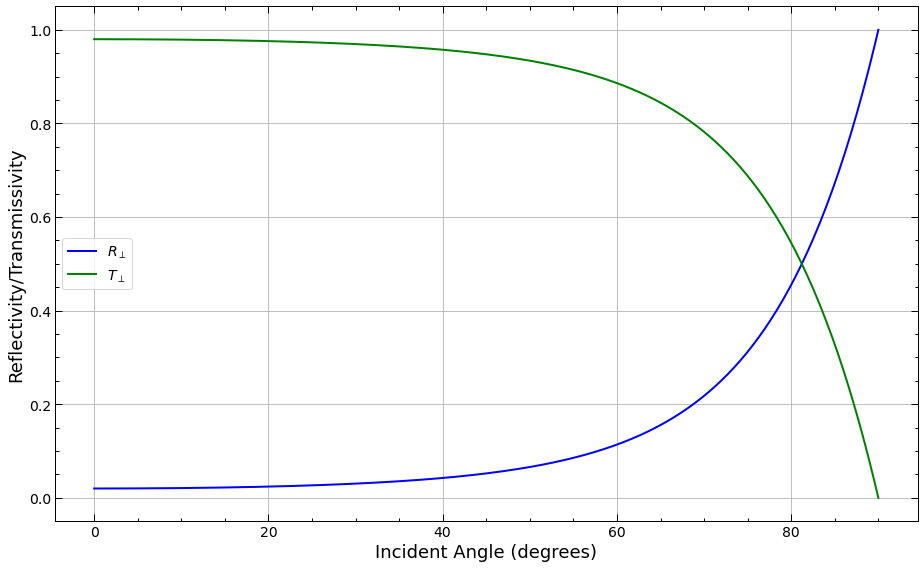

In [21]:

### Plot: Perpendicular Polarization


fig4, ax4 = plt.subplots(figsize=(8*1.618,8))

ax4.plot(theta_i_deg2, Rperp2, label=r'$R_{\perp}$', color='blue', linewidth=2)
ax4.plot(theta_i_deg2, Tperp2, label=r'$T_{\perp}$', color='green', linewidth=2)

# set the tick mark parameters
ax4.minorticks_on()
ax4.tick_params(which='both',direction="in",width=1, labelsize=14)
ax4.tick_params(which='major',length=7)
ax4.tick_params(which='minor',length=3.5)
ax4.xaxis.set_ticks_position('both')
ax4.yaxis.set_ticks_position('both')

# Frame and labels
ax4.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax4.set_ylabel('Reflectivity/Transmissivity', fontsize=18)
# ax4.set_title('Perpendicular Polarization')

ax4.legend(fontsize=14, loc='center left')
ax4.grid(True)

fig4.tight_layout()
fig4.show()


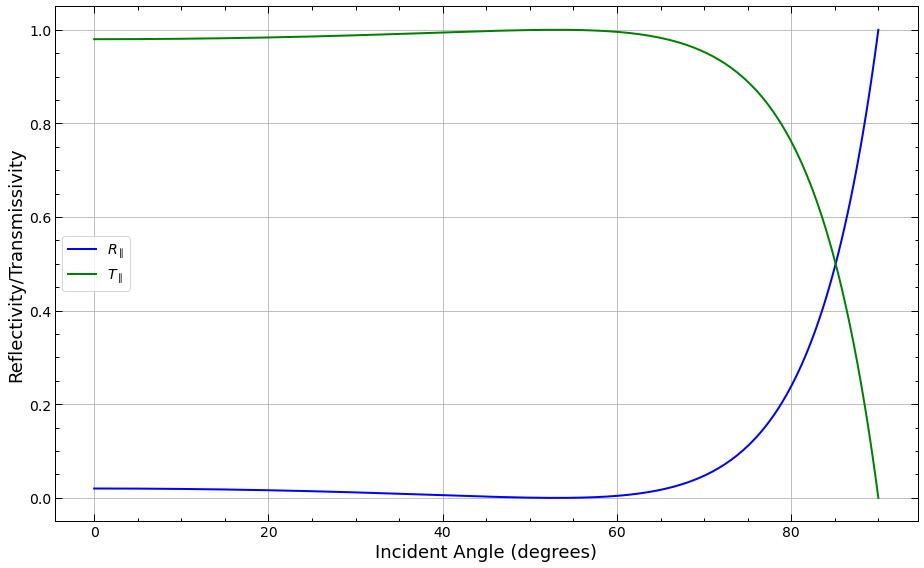

In [22]:

### Plot: Parallel Polarization

fig5, ax5 = plt.subplots(figsize=(8*1.618,8))

ax5.plot(theta_i_deg2, Rpar2, label=r'$R_{\parallel}$', color='blue', linewidth=2)
ax5.plot(theta_i_deg2, Tpar2, label=r'$T_{\parallel}$', color='green', linewidth=2)

# set the tick mark parameters
ax5.minorticks_on()
ax5.tick_params(which='both',direction="in",width=1, labelsize=14)
ax5.tick_params(which='major',length=7)
ax5.tick_params(which='minor',length=3.5)
ax5.xaxis.set_ticks_position('both')
ax5.yaxis.set_ticks_position('both')

# Frame and labels
ax5.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax5.set_ylabel('Reflectivity/Transmissivity', fontsize=18)
# ax5.set_title('Perpendicular Polarization')

ax5.legend(fontsize=14, loc='center left')
ax5.grid(True)

fig5.tight_layout()
fig5.show()


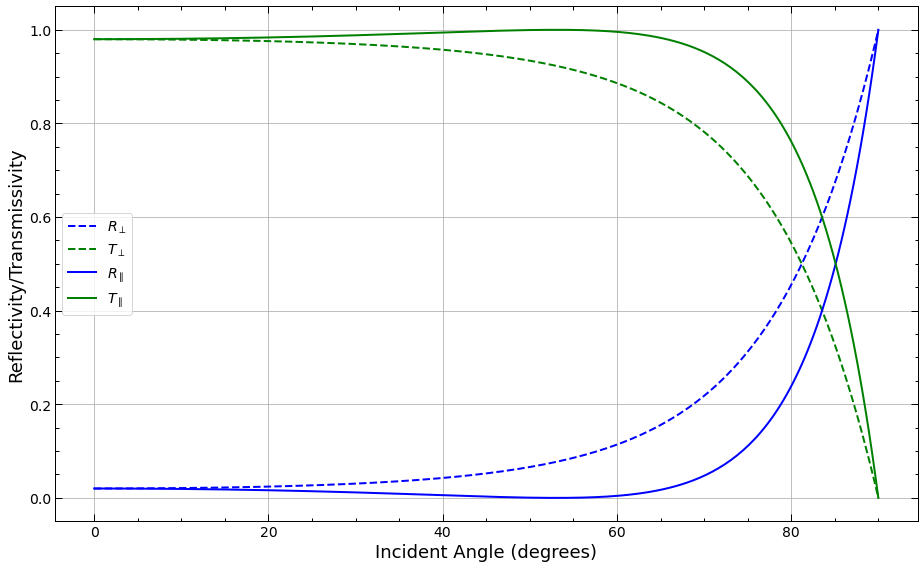

In [23]:
### Plot: Both Polarizations

fig6, ax6 = plt.subplots(figsize=(8*1.618,8))

ax6.plot(theta_i_deg2, Rperp2, label=r'$R_{\perp}$', color='blue', linewidth=2, linestyle='--')
ax6.plot(theta_i_deg2, Tperp2, label=r'$T_{\perp}$', color='green', linewidth=2, linestyle='--')
ax6.plot(theta_i_deg2, Rpar2, label=r'$R_{\parallel}$', color='blue', linewidth=2)
ax6.plot(theta_i_deg2, Tpar2, label=r'$T_{\parallel}$', color='green', linewidth=2)

# set the tick mark parameters
ax6.minorticks_on()
ax6.tick_params(which='both',direction="in",width=1, labelsize=14)
ax6.tick_params(which='major',length=7)
ax6.tick_params(which='minor',length=3.5)
ax6.xaxis.set_ticks_position('both')
ax6.yaxis.set_ticks_position('both')

# Frame and labels
ax6.set_xlabel('Incident Angle (degrees)', fontsize=18)
ax6.set_ylabel('Reflectivity/Transmissivity', fontsize=18)
# ax6.set_title('Both Polarizations')

ax6.legend(fontsize=14, loc='center left')
ax6.grid(True)

fig6.tight_layout()
fig6.show()


### Make interactive plot with `matplotlib`

In [24]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_fresnel_power(ni, nt):
    plt.close('all') # Clear existing figures to prevent memory/output bloat
    
    # 1. Setup Data
    numangles = 256
    theta_i_deg = np.linspace(0, 90, numangles)
    theta_i = np.radians(theta_i_deg)
    
    ni_safe = max(ni, 1e-6)
    sin_t = ni_safe / nt * np.sin(theta_i)
    critical_angle_rad = np.arcsin(nt/ni_safe) if ni_safe > nt else np.pi/2
    test_tir = theta_i > critical_angle_rad
    
    theta_t = np.arcsin(np.clip(sin_t, -1, 1))
    theta_t[test_tir] = np.pi/2 

    cos_i = np.cos(theta_i)
    cos_t = np.cos(theta_t)
    
    # Amplitude Coefficients
    r_perp = (ni_safe * cos_i - nt * cos_t) / (ni_safe * cos_i + nt * cos_t)
    t_perp = (2 * ni_safe * cos_i) / (ni_safe * cos_i + nt * cos_t)
    r_par = (nt * cos_i - ni_safe * cos_t) / (nt * cos_i + ni_safe * cos_t)
    t_par = (2 * ni_safe * cos_i) / (nt * cos_i + ni_safe * cos_t)

    # Power Coefficients
    R_perp = r_perp**2
    R_par = r_par**2
    T_factor = np.divide((nt * cos_t), (ni_safe * cos_i), out=np.zeros_like(cos_i), where=cos_i!=0)
    T_perp = (t_perp**2) * T_factor
    T_par = (t_par**2) * T_factor

    R_perp[test_tir], T_perp[test_tir] = 1.0, 0.0
    R_par[test_tir], T_par[test_tir] = 1.0, 0.0

    # 2. Setup Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(theta_i_deg, R_perp, label=r'$R_{\perp}$ (s-pol)', color='blue', lw=2, ls='--')
    ax.plot(theta_i_deg, T_perp, label=r'$T_{\perp}$ (s-pol)', color='green', lw=2, ls='--')
    ax.plot(theta_i_deg, R_par, label=r'$R_{\parallel}$ (p-pol)', color='blue', lw=2)
    ax.plot(theta_i_deg, T_par, label=r'$T_{\parallel}$ (p-pol)', color='green', lw=2)

    brew_deg = np.degrees(np.arctan(nt / ni_safe))
    ax.axvline(brew_deg, color='purple', ls=':', alpha=0.5, label=fr'$\theta_B = {brew_deg:.1f}^\circ$')

    if ni_safe > nt:
        crit_deg = np.degrees(critical_angle_rad)
        ax.axvline(crit_deg, color='red', ls=':', alpha=0.5, label=fr'$\theta_c = {crit_deg:.1f}^\circ$')

    ax.set_xlabel('Incident Angle (degrees)', fontsize=18)
    ax.set_ylabel('Reflectivity / Transmissivity', fontsize=18)
    ax.set_ylim(-0.05, 1.1)
    ax.set_xlim(0, 90)
    ax.grid(True, ls=':', alpha=0.6)
    ax.tick_params(which='both', direction="in", width=1, labelsize=14)
    ax.minorticks_on()
    ax.legend(fontsize=12, loc='center left', frameon=True, ncol=2)
    
    # Adding a semicolon or explicitly calling plt.show() usually cleans up the 'double' display
    plt.show()

# 3. INTERACT
interact(
    plot_fresnel_power, 
    ni=FloatSlider(min=1.0, max=2.5, step=0.05, value=1.0, description='n₁ (incident)', continuous_update=False),
    nt=FloatSlider(min=1.0, max=2.5, step=0.05, value=1.5, description='n₂ (transmitted)', continuous_update=False)
);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-06-reflectivity_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-06.html) (direct link: [ch02-06-reflectivity_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-06-reflectivity_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.